# Nhóm 3: so sánh năm phương pháp giải BMP

Nguồn: `results/data/group3_official_strong_lb_120s.csv`, gồm
**113 đồ thị × 5 phương pháp = 565 lượt chạy**, thuộc cả `hb_33` và `hb_80`.
Điều kiện giới hạn thời gian và RAM được đọc từ file `.meta.json` đi kèm.

| Nhãn trên hình | Phương pháp trong CSV |
| --- | --- |
| SAT | Pairwise + Product + Incremental |
| CP | CP |
| MIP | MIP |
| CP-SAT | CP-SAT |
| Gurobi | Gurobi |

Notebook tạo năm hình: trạng thái kết quả, performance profile, gap tương đối,
RAM đỉnh và thời gian dựng mô hình/giải. Nghiệm hợp lệ là các dòng có trạng thái
`FEASIBLE` hoặc `OPTIMAL` và có bandwidth. Ô bandwidth/gap trống được giữ là thiếu dữ liệu.

Chạy từ trên xuống dưới bằng kernel `.venv`. Hình được lưu dưới dạng PNG
ngay trong `results/visualization/png/`.


In [14]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter, NullFormatter
from IPython.display import display

METHODS = ["Pairwise + Product + Incremental", "CP", "MIP", "CP-SAT", "Gurobi"]
METHOD_LABELS = ["SAT", "CP", "MIP", "CP-SAT", "Gurobi"]
METHOD_SHORT = dict(zip(METHODS, METHOD_LABELS))
METHOD_COLORS = dict(zip(METHODS, ["#4C78A8", "#54A24B", "#E45756", "#F58518", "#B279A2"]))
STATUSES = ["OPTIMAL", "FEASIBLE", "TIMEOUT", "ERROR"]
VALID_STATUSES = {"OPTIMAL", "FEASIBLE"}
STATUS_COLORS = dict(zip(STATUSES, ["#2E8B57", "#4C78A8", "#ECA82C", "#C44E52"]))
DATA_GROUPS = ["hb_33", "hb_80"]

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "results/data/group3_official_strong_lb_120s.csv").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Không tìm thấy results/data/group3_official_strong_lb_120s.csv")
csv_path = root / "results/data/group3_official_strong_lb_120s.csv"
metadata = json.loads(csv_path.with_suffix(".meta.json").read_text(encoding="utf-8-sig"))
time_limit_seconds = float(metadata["time_limit_seconds"])
memory_limit_gib = float(metadata["memory_limit_gb"])
memory_limit_mib = memory_limit_gib * 1024
figure_dir = root / "results/visualization/png"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.rcdefaults()
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "figure.titlesize": 15,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
})
saved_figures = []

def save_figure(fig, stem):
    path = figure_dir / f"{stem}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    saved_figures.append(path)

print("Nguồn dữ liệu:", csv_path)
print(f"Giới hạn: {time_limit_seconds:g} giây/lượt; {memory_limit_gib:g} GiB RAM")


Nguồn dữ liệu: d:\EXP\year-3-semester-1\Contemporary-issues-in-computer-science\Bandwidth-Minimization-Problem\results\data\group3_official_strong_lb_120s.csv
Giới hạn: 120 giây/lượt; 8 GiB RAM


## Đọc dữ liệu và xác định tập so sánh

Kiểm tra mỗi đồ thị có đúng một dòng cho từng phương pháp, trạng thái hợp lệ và
`gap = bandwidth − lower_bound` khi có nghiệm. Cột `gap` trong CSV là chênh lệch
tuyệt đối; phần trăm gap được tính riêng ở dưới.

Hình 1–2 dùng toàn bộ đồ thị. Hình 3 dùng các lượt có nghiệm hợp lệ của từng phương pháp,
được lọc độc lập theo trạng thái của chính phương pháp đó. Hình 5 dùng cùng tập đồ thị
có nghiệm hợp lệ ở cả năm phương pháp. Hình 4 giữ cả lượt `TIMEOUT`/`ERROR` có số liệu RAM
để phản ánh tài nguyên đã được sử dụng trước khi kết thúc hoặc bị dừng.


In [15]:
group3 = pd.read_csv(csv_path)
required = {
    "instance", "n", "m", "method", "status", "bandwidth", "lower_bound", "gap",
    "total_time", "build_time", "solve_time", "peak_ram_mb",
}
if not required.issubset(group3.columns):
    raise ValueError(f"CSV thiếu cột: {required - set(group3.columns)}")
always_present = sorted(required - {"bandwidth", "gap"})
if group3[always_present].isna().any().any():
    raise ValueError("CSV thiếu dữ liệu ngoài các ô bandwidth/gap được phép trống")
if set(group3["method"]) != set(METHODS):
    raise ValueError("CSV không có đúng năm phương pháp Nhóm 3")
if not group3["status"].isin(STATUSES).all():
    raise ValueError("CSV có trạng thái không hợp lệ")
if group3.duplicated(["instance", "method"]).any():
    raise ValueError("Có cặp đồ thị/phương pháp bị lặp")

numeric_columns = sorted(required - {"instance", "method", "status"})
for column in numeric_columns:
    group3[column] = pd.to_numeric(group3[column], errors="raise")
mandatory_numeric = [c for c in numeric_columns if c not in {"bandwidth", "gap"}]
if not np.isfinite(group3[mandatory_numeric].to_numpy(dtype=float)).all():
    raise ValueError("CSV có số liệu không hữu hạn")
for column in ("bandwidth", "gap"):
    present = group3[column].dropna()
    if not np.isfinite(present.to_numpy(dtype=float)).all():
        raise ValueError(f"Cột {column} có giá trị không hữu hạn")
if (group3[numeric_columns] < 0).any().any() or (group3["n"] < 1).any():
    raise ValueError("Số liệu phải không âm và số đỉnh phải dương")
if (group3.groupby("instance")[["n", "m"]].nunique() != 1).any().any():
    raise ValueError("Số đỉnh/cạnh không nhất quán giữa các phương pháp")
if not group3["bandwidth"].isna().equals(group3["gap"].isna()):
    raise ValueError("Bandwidth và gap phải cùng có hoặc cùng thiếu dữ liệu")

instance_group = {}
for data_group in DATA_GROUPS:
    paths = sorted((root / "data" / data_group).glob("*.mtx.rnd"))
    if not paths:
        raise ValueError(f"Không tìm thấy đồ thị trong data/{data_group}")
    for path in paths:
        name = path.name.removesuffix(".mtx.rnd")
        if name in instance_group:
            raise ValueError(f"Tên đồ thị bị lặp giữa hai nhóm: {name}")
        instance_group[name] = data_group
instance_count = len(instance_group)
if set(group3["instance"]) != set(instance_group):
    raise ValueError("Tập đồ thị trong CSV không khớp hb_33 và hb_80")
if len(group3) != instance_count * len(METHODS):
    raise ValueError("CSV chưa có đủ lượt chạy cho các đồ thị/phương pháp")
group3["data_group"] = group3["instance"].map(instance_group)

valid_mask = group3["status"].isin(VALID_STATUSES)
if group3.loc[valid_mask, "bandwidth"].isna().any():
    raise ValueError("Dòng FEASIBLE/OPTIMAL thiếu bandwidth")
has_bandwidth = group3["bandwidth"].notna()
if (group3.loc[has_bandwidth, "bandwidth"] >= group3.loc[has_bandwidth, "n"]).any():
    raise ValueError("Bandwidth nằm ngoài miền 0..n-1")
differences = group3.loc[has_bandwidth, "bandwidth"] - group3.loc[has_bandwidth, "lower_bound"]
if differences.lt(-1e-5).any():
    raise ValueError("Cận dưới lớn hơn bandwidth")
if not np.allclose(group3.loc[has_bandwidth, "gap"], differences.clip(lower=0), rtol=0, atol=1e-4):
    raise ValueError("Gap trong CSV không bằng bandwidth trừ cận dưới")
optimal_mask = group3["status"].eq("OPTIMAL")
if not np.allclose(group3.loc[optimal_mask, "bandwidth"], group3.loc[optimal_mask, "lower_bound"], rtol=0, atol=1e-5):
    raise ValueError("Dòng OPTIMAL không có hai cận khớp nhau")

valid_records = group3.loc[valid_mask].copy()
valid_records["relative_gap_pct"] = np.where(
    valid_records["bandwidth"].eq(0), 0.0,
    100 * valid_records["gap"] / valid_records["bandwidth"].replace(0, np.nan),
)
status_counts = pd.crosstab(group3["method"], group3["status"]).reindex(
    index=METHODS, columns=STATUSES, fill_value=0,
)
valid_bandwidth = group3.assign(
    valid_bandwidth=group3["bandwidth"].where(valid_mask)
).pivot(index="instance", columns="method", values="valid_bandwidth").reindex(
    index=sorted(instance_group), columns=METHODS,
)
common_instances = valid_bandwidth.index[valid_bandwidth.notna().all(axis=1)]
common_count = len(common_instances)
if common_count == 0:
    raise ValueError("Không có đồ thị nào có nghiệm hợp lệ ở cả năm phương pháp")
common_records = valid_records[valid_records["instance"].isin(common_instances)].copy()
ram_records = group3[group3["peak_ram_mb"].gt(0)].copy()
if ram_records.empty:
    raise ValueError("Không có số liệu RAM dương để vẽ")

print(f"Đã kiểm tra: {len(group3)} dòng, {instance_count} đồ thị, {len(METHODS)} phương pháp")
print(f"Lượt có nghiệm hợp lệ: {len(valid_records)}/{len(group3)}")
print(f"Ô bandwidth/gap thiếu: {group3['bandwidth'].isna().sum()} dòng; giữ nguyên là thiếu dữ liệu")
print("Gap (Hình 3): dùng tập có nghiệm hợp lệ riêng của từng phương pháp")
print(f"Tập chung cho thời gian (Hình 5): {common_count} đồ thị")
print(f"Lượt có số liệu RAM dương: {len(ram_records)}/{len(group3)}")


Đã kiểm tra: 565 dòng, 113 đồ thị, 5 phương pháp
Lượt có nghiệm hợp lệ: 543/565
Ô bandwidth/gap thiếu: 22 dòng; giữ nguyên là thiếu dữ liệu
Gap (Hình 3): dùng tập có nghiệm hợp lệ riêng của từng phương pháp
Tập chung cho thời gian (Hình 5): 98 đồ thị
Lượt có số liệu RAM dương: 565/565


## Hình 1: trạng thái kết quả của năm phương pháp

Mỗi cột gồm số lượt `OPTIMAL`, `FEASIBLE`, `TIMEOUT`, `ERROR`. Ô đầu dùng toàn bộ đồ thị;
hai ô còn lại tách `hb_33` và `hb_80`. Nhãn số chỉ đặt trong phần cột đủ cao để đọc rõ;
bảng phía dưới cung cấp đầy đủ các số đếm, kể cả phần rất nhỏ và giá trị 0.


status,OPTIMAL,FEASIBLE,TIMEOUT,ERROR
Phương pháp,,,,
SAT,5,108,0,0
CP,6,107,0,0
MIP,1,105,5,2
CP-SAT,6,106,1,0
Gurobi,1,98,14,0


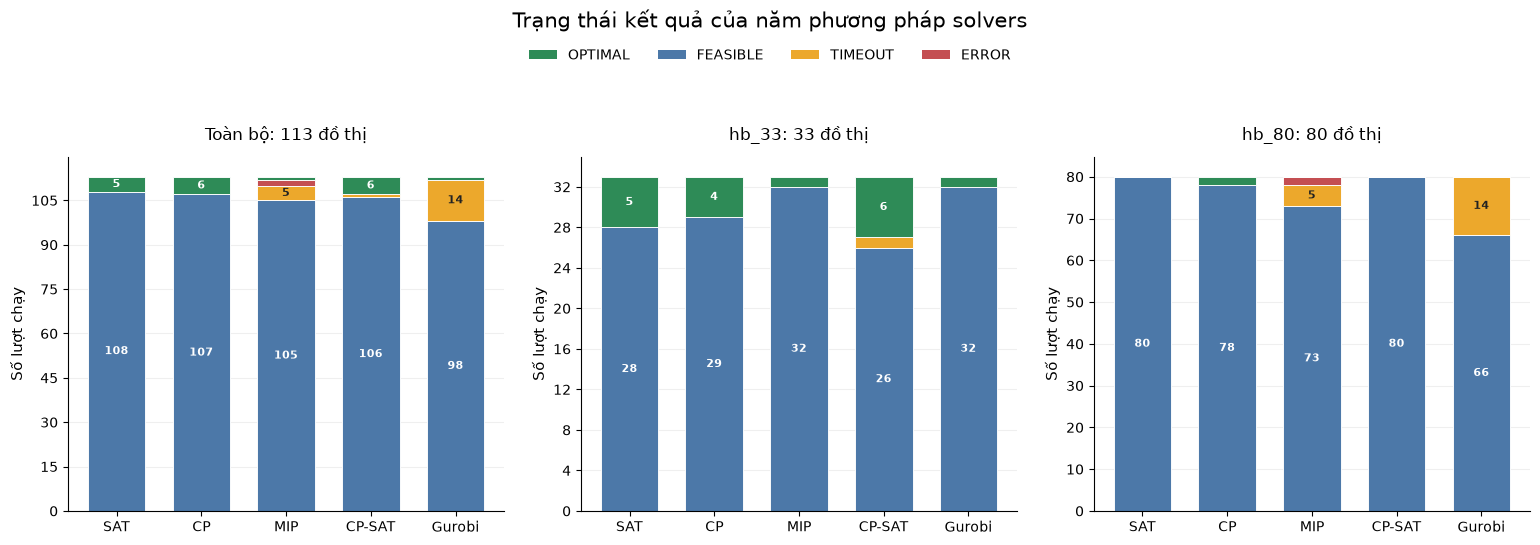

In [16]:
display(status_counts.rename(index=METHOD_SHORT).rename_axis("Phương pháp"))
scopes = [("Toàn bộ", group3)] + [
    (data_group, group3[group3["data_group"].eq(data_group)]) for data_group in DATA_GROUPS
]
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.3))
for ax, (scope_name, records) in zip(axes, scopes):
    counts = pd.crosstab(records["method"], records["status"]).reindex(
        index=METHODS, columns=STATUSES, fill_value=0,
    )
    n_graphs = records["instance"].nunique()
    positions = np.arange(len(METHODS))
    bottom = np.zeros(len(METHODS), dtype=int)
    for status in ["FEASIBLE", "TIMEOUT", "ERROR", "OPTIMAL"]:
        heights = counts[status].to_numpy()
        ax.bar(positions, heights, bottom=bottom, color=STATUS_COLORS[status],
               edgecolor="white", linewidth=0.65, width=0.68)
        for x, height, base in zip(positions, heights, bottom):
            if height >= n_graphs * 0.04:
                ax.text(x, base + height / 2, str(int(height)), ha="center", va="center",
                        color="#222222" if status == "TIMEOUT" else "white",
                        fontsize=8, fontweight="bold")
        bottom += heights
    ax.set_xticks(positions, METHOD_LABELS, fontsize=10)
    ax.set_title(f"{scope_name}: {n_graphs} đồ thị", pad=12)
    ax.set_ylim(0, n_graphs * 1.06)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.2)
    ax.set_ylabel("Số lượt chạy")
fig.suptitle("Trạng thái kết quả của năm phương pháp solvers", y=1.02)
fig.legend([Patch(facecolor=STATUS_COLORS[s]) for s in STATUSES], STATUSES,
           loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.9), w_pad=2)
save_figure(fig, "group3_01_status")
plt.show()


## Hình 2: performance profile về chất lượng nghiệm

Với từng đồ thị, lấy bandwidth nhỏ nhất trong các nghiệm hợp lệ làm mốc quan sát.
Tỷ lệ `r = bandwidth / bandwidth tốt nhất quan sát được`; `r = 1` nghĩa là đạt mốc này,
không đồng nghĩa đã chứng minh tối ưu.

Trục Y luôn chia cho toàn bộ đồ thị. Dòng `TIMEOUT`/`ERROR` không đạt mọi ngưỡng hữu hạn.
Trục X dùng thang log để nhìn rõ cả các tỷ lệ gần 1 và những trường hợp chênh lệch rất lớn.
Đường cao hơn ở cùng ngưỡng thể hiện độ bao phủ/chất lượng tốt hơn.


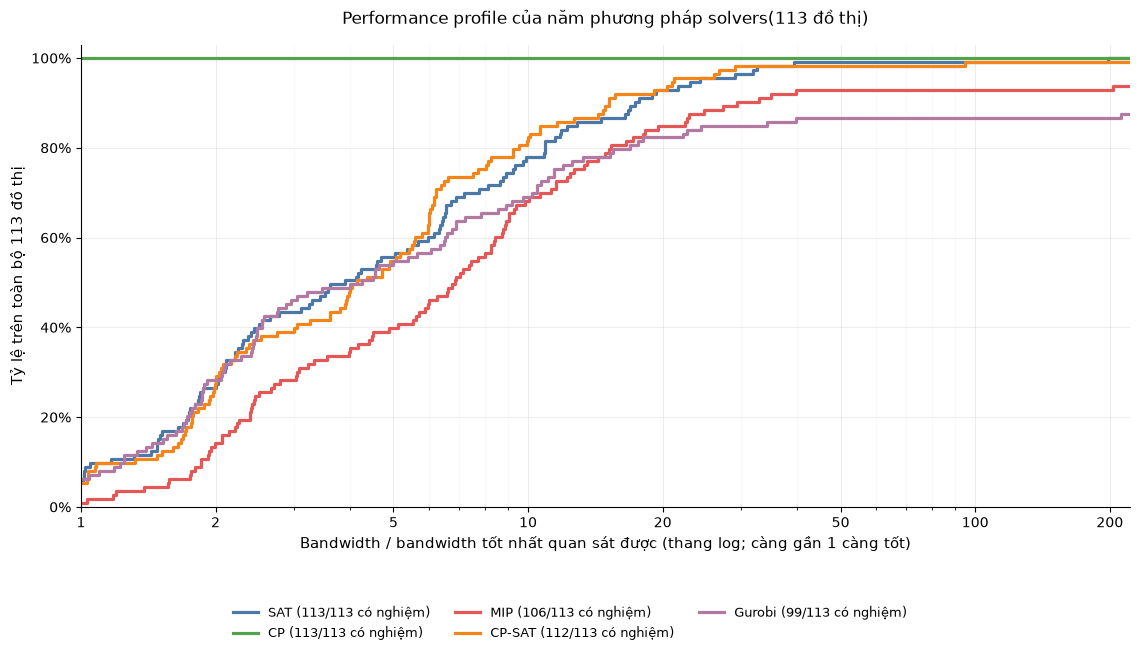

,Có nghiệm hợp lệ,Đạt bandwidth tốt nhất (kể cả hòa),Độ bao phủ tối đa (%)
Phương pháp,,,
SAT,113,6,100.00
CP,113,113,100.00
MIP,106,1,93.81
CP-SAT,112,6,99.12
Gurobi,99,7,87.61


In [22]:
best_observed = valid_bandwidth.min(axis=1)
if best_observed.isna().any():
    raise ValueError("Có đồ thị chưa có nghiệm hợp lệ để xác định mốc chất lượng")
quality_ratios = valid_bandwidth.div(best_observed.replace(0, np.nan), axis=0)
zero_best = best_observed.eq(0)
if zero_best.any():
    quality_ratios.loc[zero_best] = np.where(valid_bandwidth.loc[zero_best].eq(0), 1.0, np.inf)
quality_ratios = quality_ratios.fillna(np.inf)
finite_values = quality_ratios.to_numpy()[np.isfinite(quality_ratios.to_numpy())]
profile_xmax = max(1.2, float(finite_values.max()) * 1.05)

fig, ax = plt.subplots(figsize=(11.5, 6.5))
profile_rows = []
for method in METHODS:
    ratios = quality_ratios[method].to_numpy()
    finite = np.sort(ratios[np.isfinite(ratios)])
    thresholds = np.unique(np.r_[1.0, finite, profile_xmax])
    coverage = (finite[:, None] <= thresholds[None, :]).sum(axis=0) / instance_count * 100
    ax.step(thresholds, coverage, where="post", color=METHOD_COLORS[method], linewidth=2.3,
            label=f"{METHOD_SHORT[method]} ({len(finite)}/{instance_count} có nghiệm)")
    profile_rows.append({
        "Phương pháp": METHOD_SHORT[method],
        "Có nghiệm hợp lệ": len(finite),
        "Đạt bandwidth tốt nhất (kể cả hòa)": int(np.isclose(ratios, 1.0).sum()),
        "Độ bao phủ tối đa (%)": round(len(finite) / instance_count * 100, 2),
    })
profile_summary = pd.DataFrame(profile_rows).set_index("Phương pháp")
ax.set_xscale("log")
ticks = [t for t in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000] if t <= profile_xmax]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(1, profile_xmax)
ax.set_ylim(0, 103)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_xlabel("Bandwidth / bandwidth tốt nhất quan sát được (thang log; càng gần 1 càng tốt)")
ax.set_ylabel(f"Tỷ lệ trên toàn bộ {instance_count} đồ thị")
ax.set_title(f"Performance profile của năm phương pháp solvers({instance_count} đồ thị)", pad=15)
ax.grid(which="major", alpha=0.22)
ax.grid(which="minor", axis="x", alpha=0.07)
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.01),
           ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.12, 1, 1))
save_figure(fig, "group3_02_quality_profile")
plt.show()
display(profile_summary)


## Hình 3: gap tương đối trên tập có nghiệm riêng của từng phương pháp

Tính **gap tương đối (%) = 100 × (bandwidth − lower_bound) / bandwidth**,
tương đương `100 × gap / bandwidth` từ CSV. Trường hợp bandwidth bằng 0 và hai cận khớp
nhau được quy ước gap bằng 0%.

Mỗi phương pháp giữ tất cả các dòng `FEASIBLE` hoặc `OPTIMAL` có bandwidth hợp lệ.
Dòng `TIMEOUT`/`ERROR` bị loại riêng cho phương pháp đó; kết quả của phương pháp khác
trên cùng đồ thị không ảnh hưởng đến việc đưa dòng có nghiệm vào hình. Vì vậy, số lượng
và tập đồ thị của các phương pháp có thể khác nhau; số đồ thị được ghi dưới từng hộp.

Gap càng nhỏ thì khoảng cách tới cận dưới đã ghi nhận càng nhỏ; 0% nghĩa là hai cận khớp nhau.
Hình 2 so sánh nghiệm với mốc tốt nhất quan sát được, còn hình này dùng cận dưới mà từng
phương pháp ghi nhận. Chấm là từng lượt chạy, hộp là tứ phân vị, đường đậm là trung vị.


,Số đồ thị,Q1 gap (%),Trung vị gap (%),Q3 gap (%),OPTIMAL
Phương pháp,,,,,
SAT,113,70.27,86.76,96.74,5
CP,113,28.57,50.98,62.50,6
MIP,106,78.63,90.30,96.93,1
CP-SAT,112,74.71,87.07,95.61,6
Gurobi,99,68.05,81.65,94.68,1


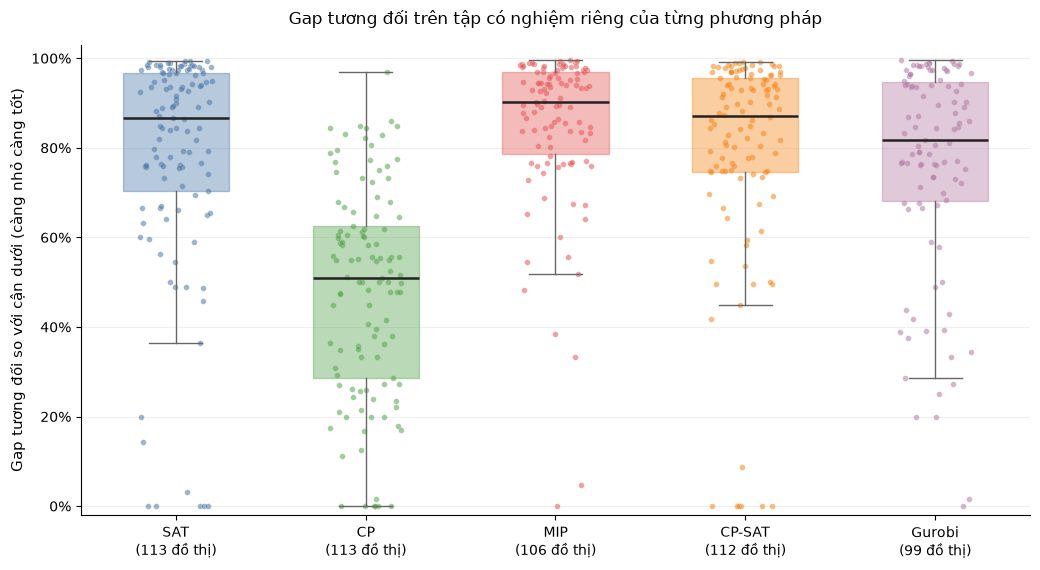

In [20]:
gap_groups = valid_records.groupby("method")["relative_gap_pct"]
gap_summary = pd.DataFrame({
    "Số đồ thị": gap_groups.size(),
    "Q1 gap (%)": gap_groups.quantile(0.25),
    "Trung vị gap (%)": gap_groups.median(),
    "Q3 gap (%)": gap_groups.quantile(0.75),
    "OPTIMAL": valid_records.assign(optimal=valid_records["status"].eq("OPTIMAL")).groupby("method")["optimal"].sum(),
}).reindex(METHODS).rename(index=METHOD_SHORT)
gap_summary.index.name = "Phương pháp"
display(gap_summary.round(2))

fig, ax = plt.subplots(figsize=(10.5, 5.8))
positions = np.arange(1, len(METHODS) + 1)
values = [valid_records.loc[valid_records["method"].eq(m), "relative_gap_pct"].to_numpy() for m in METHODS]
boxes = ax.boxplot(values, positions=positions, widths=0.56, patch_artist=True, showfliers=False,
                   medianprops={"color": "#222222", "linewidth": 1.8},
                   whiskerprops={"color": "#666666"}, capprops={"color": "#666666"})
rng = np.random.default_rng(43)
for x, method, values_i, patch in zip(positions, METHODS, values, boxes["boxes"]):
    patch.set_facecolor(METHOD_COLORS[method])
    patch.set_alpha(0.4)
    patch.set_edgecolor(METHOD_COLORS[method])
    ax.scatter(x + rng.uniform(-0.19, 0.19, len(values_i)), values_i, s=17,
               color=METHOD_COLORS[method], alpha=0.55, edgecolors="white", linewidths=0.25)
ax.set_xticks(positions, [f"{METHOD_SHORT[method]}\n({len(values_i)} đồ thị)"
                           for method, values_i in zip(METHODS, values)])
ax.set_ylim(-2, 103)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_ylabel("Gap tương đối so với cận dưới (càng nhỏ càng tốt)")
ax.set_title("Gap tương đối trên tập có nghiệm riêng của từng phương pháp", pad=15)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, "group3_03_relative_gap")
plt.show()


## Hình 4: RAM đỉnh và quan hệ với số đỉnh

Ô trái là phân bố RAM theo phương pháp; ô phải là RAM theo số đỉnh. Giữ cả các lượt
`TIMEOUT`/`ERROR` có số liệu RAM để thấy tài nguyên đã dùng trước khi dừng. Màu biểu diễn
phương pháp; chấm tròn là có nghiệm, tam giác rỗng là `TIMEOUT`, dấu X là `ERROR`.

Cột `peak_ram_mb` của benchmark được tính bằng byte chia cho `1024²`, nên đơn vị trên hình
là **MiB**. Đường ngang là giới hạn RAM từ metadata. Thang log giúp so sánh các phương pháp
có mức sử dụng bộ nhớ rất khác nhau. Đây là đỉnh RAM quan sát được trong quá trình lấy mẫu.


,Lượt có số liệu RAM,RAM trung vị (MiB),RAM lớn nhất (MiB),TIMEOUT,ERROR
Phương pháp,,,,,
SAT,113,2241.23,4238.11,0,0
CP,113,147.18,452.52,0,0
MIP,113,1281.11,8213.09,5,2
CP-SAT,113,246.18,1805.83,1,0
Gurobi,113,834.66,7653.45,14,0


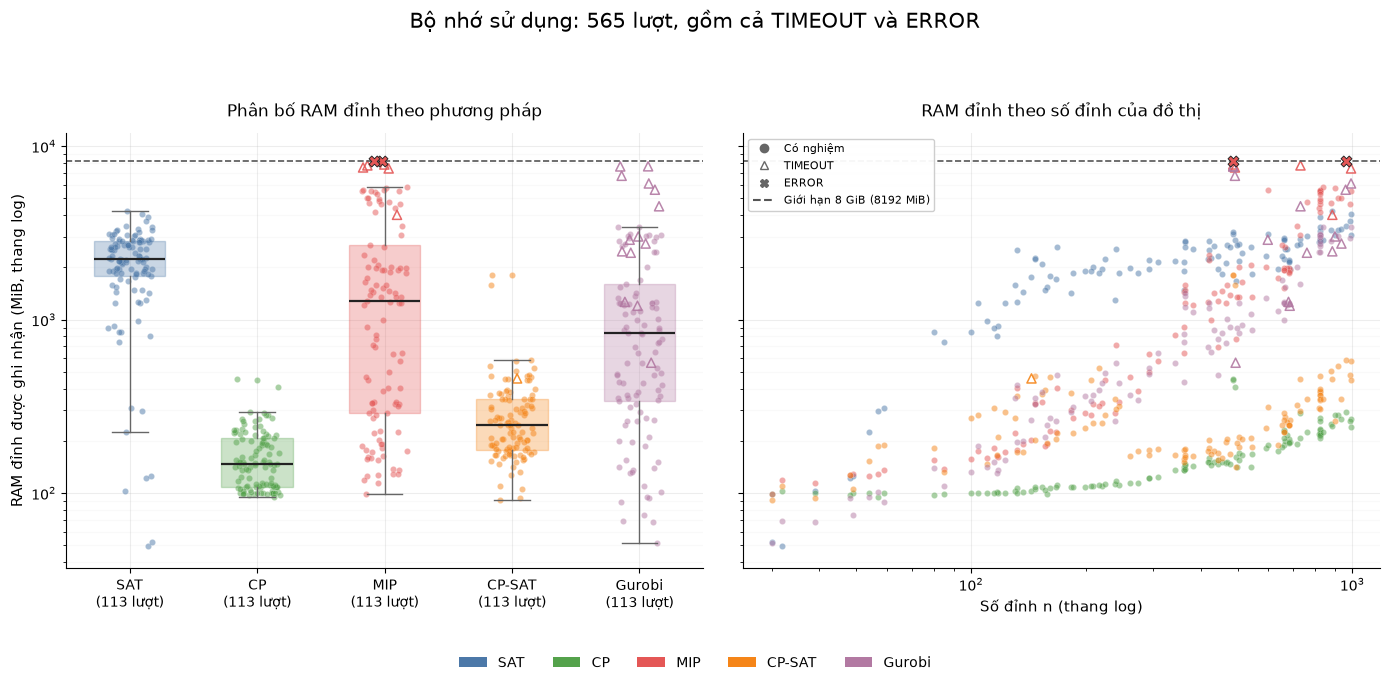

In [21]:
ram_groups = ram_records.groupby("method")["peak_ram_mb"]
ram_counts = ram_groups.size().reindex(METHODS, fill_value=0)
ram_summary = pd.DataFrame({
    "Lượt có số liệu RAM": ram_groups.size(),
    "RAM trung vị (MiB)": ram_groups.median(),
    "RAM lớn nhất (MiB)": ram_groups.max(),
    "TIMEOUT": status_counts["TIMEOUT"],
    "ERROR": status_counts["ERROR"],
}).reindex(METHODS).rename(index=METHOD_SHORT)
ram_summary.index.name = "Phương pháp"
display(ram_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6.6), sharey=True)
positions = np.arange(1, len(METHODS) + 1)
values = [ram_records.loc[ram_records["method"].eq(m), "peak_ram_mb"].to_numpy() for m in METHODS]
if any(len(values_i) == 0 for values_i in values):
    raise ValueError("Có phương pháp chưa có số liệu RAM dương")
boxes = axes[0].boxplot(values, positions=positions, widths=0.56, patch_artist=True, showfliers=False,
                       medianprops={"color": "#222222", "linewidth": 1.6},
                       whiskerprops={"color": "#666666"}, capprops={"color": "#666666"})
rng = np.random.default_rng(44)
for x, method, patch in zip(positions, METHODS, boxes["boxes"]):
    patch.set_facecolor(METHOD_COLORS[method])
    patch.set_alpha(0.3)
    patch.set_edgecolor(METHOD_COLORS[method])
    method_records = ram_records[ram_records["method"].eq(method)]
    for kind in ["solution", "TIMEOUT", "ERROR"]:
        subset = method_records[
            method_records["status"].isin(VALID_STATUSES) if kind == "solution"
            else method_records["status"].eq(kind)
        ]
        if subset.empty:
            continue
        jitter = x + rng.uniform(-0.18, 0.18, len(subset))
        for ax, xs in [(axes[0], jitter), (axes[1], subset["n"])]:
            if kind == "solution":
                ax.scatter(xs, subset["peak_ram_mb"], s=20, marker="o",
                           color=METHOD_COLORS[method], alpha=0.5, edgecolors="white", linewidths=0.25)
            elif kind == "TIMEOUT":
                ax.scatter(xs, subset["peak_ram_mb"], s=43, marker="^", facecolors="none",
                           edgecolors=METHOD_COLORS[method], linewidths=1.1, alpha=0.9)
            else:
                ax.scatter(xs, subset["peak_ram_mb"], s=62, marker="X", color=METHOD_COLORS[method],
                           edgecolors="#222222", linewidths=0.65, zorder=5)
lower_ram = float(ram_records["peak_ram_mb"].min()) * 0.75
upper_ram = max(float(ram_records["peak_ram_mb"].max()), memory_limit_mib) * 1.45
for ax in axes:
    ax.set_yscale("log")
    ax.set_ylim(lower_ram, upper_ram)
    ax.axhline(memory_limit_mib, color="#555555", linestyle="--", linewidth=1.2)
    ax.grid(which="major", alpha=0.22)
    ax.grid(which="minor", axis="y", alpha=0.07)
axes[0].set_xticks(positions, [f"{METHOD_SHORT[m]}\n({ram_counts[m]} lượt)" for m in METHODS])
axes[0].set_title("Phân bố RAM đỉnh theo phương pháp", pad=12)
axes[0].set_ylabel("RAM đỉnh được ghi nhận (MiB, thang log)")
axes[1].set_xscale("log")
axes[1].set_xlabel("Số đỉnh n (thang log)")
axes[1].set_title("RAM đỉnh theo số đỉnh của đồ thị", pad=12)
status_handles = [
    Line2D([], [], marker="o", linestyle="", color="#666666", label="Có nghiệm"),
    Line2D([], [], marker="^", linestyle="", markerfacecolor="none", color="#666666", label="TIMEOUT"),
    Line2D([], [], marker="X", linestyle="", color="#666666", label="ERROR"),
    Line2D([], [], linestyle="--", color="#555555", label=f"Giới hạn {memory_limit_gib:g} GiB ({memory_limit_mib:g} MiB)"),
]
axes[1].legend(handles=status_handles, loc="upper left", fontsize=8, framealpha=0.95)
fig.legend([Patch(facecolor=METHOD_COLORS[m]) for m in METHODS], METHOD_LABELS,
           loc="lower center", bbox_to_anchor=(0.5, -0.01), ncol=5, frameon=False)
fig.suptitle(f"Bộ nhớ sử dụng: {len(ram_records)} lượt, gồm cả TIMEOUT và ERROR", y=1.01)
fig.tight_layout(rect=(0, 0.07, 1, 0.95), w_pad=2.5)
save_figure(fig, "group3_04_memory")
plt.show()
